<a href="https://colab.research.google.com/github/CLAIR-LAB-TECHNION/physical-ai-workshop/blob/main/material/Day%201/CLAIR-PAI-WS-Lab-1.1-TaskPlanning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![CLAIR, Taub Faculty of Computer Science, Technion](https://raw.githubusercontent.com/CLAIR-LAB-TECHNION/physical-ai-workshop/main/assets/workshop-banner.png)

Written by: [Guy Azran](https://scholar.google.com/citations?user=bxhQv1kAAAAJ) and [Sarah Keren](https://sarahk.cs.technion.ac.il/)

#### Reason. Plan. Act. | Physical AI Workshop

# Tutorial 1.1: Task Planning

Our focus in this workshop is on settings in which robotic agents need to perform complex tasks that require high-level reasoning and planning, on one hand,
and an understanding of how to move and operate in the physical environment, on the other hand.
Since we are interested in complex tasks, simply learning an optimal policy from previously performed trajectories is insufficient.

In our settings of interest, we require both the ability to perform **task planning**, which focuses on high-level decision-making and on choosing a sequence of actions that should be executed to achieve a goal, and **motion planning**, which deals with the low-level details of generating feasible motions to execute those tasks safely and efficiently.

This first tutorial is all about **task planning**. We will:

* describe a task in a formal, machine-readable language (PDDL),
* hand it to an off-the-shelf planner and get back a plan,
* see how planners find plans (state-space search and heuristics),
* watch our plans being executed in a simple simulator,
* and, finally, ask what is missing when the "executor" is a physical robot.

**No GPU needed for this tutorial.**

# Setup

This notebook is standalone: everything it needs is installed by the cell below. We will meet each of these libraries when we need it.

In [ ]:
# unified-planning: a common python interface to many planners. up-fast-downward: the Fast Downward planner.
!pip install -q unified-planning up-fast-downward

# pddlgym: a small simulator for PDDL problems (we install it without its outdated pinned dependencies).
!pip install -q --no-deps pddlgym
!pip install -q "gym>=0.26" imageio networkx scikit-image

# mediapy: video display in notebooks (requires ffmpeg).
!pip install -q mediapy
!command -v ffmpeg >/dev/null || (apt-get -qq update && apt-get -qq install -y ffmpeg)

# Running example: Blocks World

You are probably familiar with the blocks world (BW) domain, a classic problem domain used for testing automated planning methods and systems. A problem instance (see example below) typically involves a set of blocks that can be stacked on top of each other. The goal is to move blocks from an initial configuration to a desired final configuration, using a set of actions.

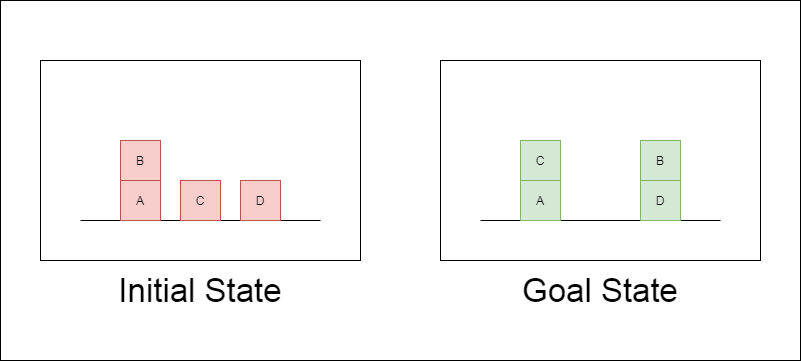

In its basic form, BW comprises the following elements:

**Blocks**: there are several blocks, each with a unique identifier. Here, blocks are represented by letters (A, B, C, D).

**Initial State:** the initial configuration of the blocks, including the positions of each block.

**Goal State:** The desired final configuration of the blocks.

**Actions:** A set of actions that can be performed to manipulate the blocks. The robot can *pick up* a block from the table and *put* it *down* on the table. It can also *stack* a block on top of another block or *unstack* a block from another block. Each action has preconditions (conditions that must be true for the action to be applicable) and effects (changes that occur when the action is executed). For example, the robot can pick up or unstack a block only if it is *clear*, i.e., there are no other blocks on top of it, and only if its hand is empty.

BW is often used as an introductory example of automated planning because its simplified form is simple to understand yet complex enough to demonstrate important planning concepts and challenges.
To solve a BW planning problem, a state space search is typically performed to find a sequence of actions that transforms the initial state into the goal state.

❓ **Before reading on, solve the instance in the picture yourself. How many actions did you need? Are you sure there is no shorter solution?**

# Modeling Blocks World with PDDL

Above we described blocks world in natural language. This is not a formal definition of the problem and is not readable by a computer (at least not deterministically). Luckily, there is a formal language for describing such problems.

**PDDL** (the Planning Domain Definition Language) is a long-standing standard for describing planning problems, introduced in [this paper](https://www.semanticscholar.org/paper/PDDL-the-planning-domain-definition-language-McDermott-Ghallab/d82c6b8081343b2eae63d45feefe630233ad60e1) in 1998. The syntax is similar to Lisp, and it is designed to be both human-readable and machine-readable. PDDL descriptions are typically divided into two parts:

* the **domain**, which captures the general predicates and actions that define the environment, and
* the **problem**, which specifies the objects of a particular instance, its initial state, and its goal.

This division separates general knowledge about the domain from specific instances within that domain, making it easy to reuse and adapt planning domains. Here is the blocks world domain:

In [ ]:
DOMAIN = """
(define (domain blocks)
    (:requirements :strips :typing)
    (:types block robot)
    (:predicates
        (on ?x - block ?y - block)
        (ontable ?x - block)
        (clear ?x - block)
        (handempty ?r - robot)
        (holding ?x - block)
    )

    (:action pick-up
        :parameters (?x - block ?r - robot)
        :precondition (and (clear ?x) (ontable ?x) (handempty ?r))
        :effect (and (not (ontable ?x))
                     (not (clear ?x))
                     (not (handempty ?r))
                     (holding ?x))
    )

    (:action put-down
        :parameters (?x - block ?r - robot)
        :precondition (holding ?x)
        :effect (and (not (holding ?x))
                     (clear ?x)
                     (handempty ?r)
                     (ontable ?x))
    )

    (:action stack
        :parameters (?x - block ?y - block ?r - robot)
        :precondition (and (holding ?x) (clear ?y))
        :effect (and (not (holding ?x))
                     (not (clear ?y))
                     (clear ?x)
                     (handempty ?r)
                     (on ?x ?y))
    )

    (:action unstack
        :parameters (?x - block ?y - block ?r - robot)
        :precondition (and (on ?x ?y) (clear ?x) (handempty ?r))
        :effect (and (holding ?x)
                     (clear ?y)
                     (not (clear ?x))
                     (not (handempty ?r))
                     (not (on ?x ?y)))
    )
)
"""

Let's go over the parts of the domain:

* `:requirements` lists the PDDL features the domain uses. `:strips` means basic add/delete effects and conjunctive preconditions; `:typing` means objects have types.
* `:types` declares the types of objects. Here we have blocks and a robot.
* `:predicates` are the facts that can be true or false in a state. `(on ?x ?y)` means block `?x` is on block `?y`; `?x` is a *variable* (parameter) that will be filled in by an actual object.
* Each `:action` has `:parameters`, a `:precondition` that must hold for the action to be applicable, and an `:effect` that describes what changes. Facts wrapped in `not` become false ("delete effects"), the rest become true ("add effects"). Anything not mentioned stays as it was.

And here is the problem instance from the picture above:

In [ ]:
PROBLEM = """
(define (problem blocks-4)
    (:domain blocks)
    (:objects
        a b c d - block
        rob - robot
    )
    (:init
        (ontable a) (on b a) (clear b)
        (ontable c) (clear c)
        (ontable d) (clear d)
        (handempty rob)
    )
    (:goal (and (on c a) (on b d)))
)
"""

Note that the goal is *partial*: it only says where `c` and `b` should be. Any state in which both facts hold is a goal state, no matter where `a` and `d` are.

❓ **Why do we need the `robot` object? Would the model be wrong without it?**

Including the robot as an explicit object (rather than a parameterless `(handempty)` predicate) is not necessary for this instance, but it makes it trivial to upgrade the problem to multiple robots. Modeling choices like this one are much easier to make at the start than to change later.

❓ **Is this a good enough representation of a robot stacking blocks? What is missing here to capture the complexities of the real-world setting?**

We will dive into this question at the end of the tutorial. Let's first solve the problem.

# Task Planning with the Unified Planning Framework

Planning problems come in different shapes and sizes, and different planners support different types of problems. Even within PDDL, there is a multitude of features (the `:requirements`), making it difficult for one planner to support them all. The [Unified Planning Framework](https://github.com/aiplan4eu/unified-planning) (UPF, or just `unified_planning`) is the de-facto standard for defining and solving planning problems in Python. It provides a common interface for defining planning problems, regardless of the underlying representation or planner being used.

UPF lets us define problems directly in Python (see the [documentation](https://unified-planning.readthedocs.io/en/latest/notebooks/tutorial/modeling.html)), but it can also read PDDL, so let's load the domain and problem we wrote above.

In [ ]:
import unified_planning as up
from unified_planning.io import PDDLReader
from unified_planning.shortcuts import get_environment

get_environment().credits_stream = None  # keep the output clean (planners print their credits otherwise)

problem = PDDLReader().parse_problem_string(DOMAIN, PROBLEM)
problem

Looking at the problem object above, we can see that it captures everything defined in the PDDL:

* `fluents`: the predicates defined in the domain (UPF calls them *fluents* because, in general, they may also have numeric values),
* `actions`: the actions defined in the domain, with their parameters, preconditions and effects,
* `objects`: the objects declared in the problem, together with their types,
* `initial values`: the initial state (UPF lists the value of every fluent, not only the true ones),
* `goals`: the goal condition.

## Solving with Fast Downward

We installed [Fast Downward](https://www.fast-downward.org/), which has long been one of the most efficient classical planners around. UPF gives us a *oneshot planner* interface, which takes a problem and returns a plan.

In [ ]:
from unified_planning.shortcuts import OneshotPlanner

with OneshotPlanner(name="fast-downward") as planner:
    result = planner.solve(problem)

print("status:", result.status.name)
print("plan:")
for i, action in enumerate(result.plan.actions):
    print(f"  {i + 1}. {action}")

And that's it, we have a plan! Each line is an *action instance*: an action from the domain with concrete objects in place of its parameters.

❓ **Is this the plan you found by hand? Is it the same length?**

## Checking a plan

Like any software, planners can have bugs. Before trusting a plan (let alone executing it on a robot), it is good practice to *validate* it: start from the initial state, apply the actions one by one, check that each is applicable, and check that the final state satisfies the goal. UPF provides a validator that does this:

In [ ]:
from unified_planning.shortcuts import PlanValidator

with PlanValidator(problem_kind=problem.kind, plan_kind=result.plan.kind) as validator:
    print(validator.validate(problem, result.plan).status.name)

We can also do the validation by hand with UPF's *sequential simulator*, which lets us walk through states one action at a time. This is also a good opportunity to look at what a *state* is: an assignment of values to all fluents. We will show only the true ones.

In [ ]:
from unified_planning.shortcuts import SequentialSimulator


def true_facts(state, problem):
    """The set of facts (grounded fluent expressions) that hold in a state."""
    # problem.initial_values lists every grounded fluent, which is a convenient way to enumerate them all
    return {fact for fact in problem.initial_values if state.get_value(fact).is_true()}


with SequentialSimulator(problem) as simulator:
    state = simulator.get_initial_state()
    print("initial state:", sorted(map(str, true_facts(state, problem))))

    for action in result.plan.actions:
        assert simulator.is_applicable(state, action), f"{action} is not applicable!"
        state = simulator.apply(state, action)
        print(f"after {action}:", sorted(map(str, true_facts(state, problem))))

    print("goal reached:", simulator.is_goal(state))

⚒ **Task 1**: Use the simulator to list all the actions that are applicable in the initial state. Then take one of them, apply it, and list the applicable actions in the resulting state.

*Hint:* `simulator.get_applicable_actions(state)` yields `(action, parameters)` pairs. To turn such a pair into an action instance that `simulator.apply` accepts, use `simulator.apply(state, action, parameters)`.

In [ ]:
with SequentialSimulator(problem) as simulator:
    state = simulator.get_initial_state()
    # your code here

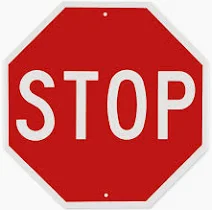

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
with SequentialSimulator(problem) as simulator:
    state = simulator.get_initial_state()

    applicable = list(simulator.get_applicable_actions(state))
    print(f"{len(applicable)} applicable actions in the initial state:")
    for action, parameters in applicable:
        print("  ", up.plans.ActionInstance(action, parameters))

    action, parameters = applicable[0]
    state = simulator.apply(state, action, parameters)
    print(f"after {up.plans.ActionInstance(action, parameters)}:", sorted(map(str, true_facts(state, problem))))

    applicable = list(simulator.get_applicable_actions(state))
    print(f"{len(applicable)} applicable actions:")
    for action, parameters in applicable:
        print("  ", up.plans.ActionInstance(action, parameters))

❓ **How many actions were applicable in the initial state? How many *states* do you think this problem has in total?** (There are only 4 blocks. Now think of 10.)

# How does a planner find a plan? State-space search

The states of the problem, together with the actions that lead from one state to another, form a (usually enormous) directed graph. Finding a plan means finding a path in this graph from the initial state to *some* goal state, i.e., a state that satisfies the goal condition. Classical planners do this with a family of algorithms called **state-space search**.

Instead of trusting Fast Downward blindly, let's implement a search ourselves. We will build the graph *on the fly* using UPF's simulator: a node stores a state, and expanding a node means applying all applicable actions to get its successors.

All the search methods we will see are special cases of **Best First Search**, which accepts as input:

1. a *frontier*, which defines the order by which nodes are explored (here, a priority queue with a priority function),
2. a *termination criterion*, defining at which point the search should stop (here: the first goal state that is popped from the frontier),
3. a flag defining whether a *closed list* is used to avoid re-exploring states.

In [ ]:
import heapq
import itertools
import math
import time


class Node:
    def __init__(self, state, parent=None, action=None, cost=0.0):
        self.state = state
        self.parent = parent
        self.action = action  # the action instance that led from parent to this node
        self.cost = cost  # g(n): cost of the path from the initial state (here every action costs 1)
        self.depth = 0 if parent is None else parent.depth + 1

    def plan(self):
        """The sequence of action instances leading from the initial state to this node."""
        actions, node = [], self
        while node.parent is not None:
            actions.append(node.action)
            node = node.parent
        return actions[::-1]


def best_first_search(problem, priority, use_closed_list=True, max_expansions=200_000):
    """Generic best-first search over the state space of a UPF problem.

    priority(node, problem) -> number. Nodes with lower priority are expanded first.
    Returns (plan or None, stats).
    """
    start_time = time.time()
    counter = itertools.count()  # tie-breaker: FIFO among equal priorities
    n_expanded = n_generated = 0

    with SequentialSimulator(problem) as simulator:
        root = Node(simulator.get_initial_state())
        frontier = [(priority(root, problem), next(counter), root)]
        closed = set()

        while frontier:
            _, _, node = heapq.heappop(frontier)

            if simulator.is_goal(node.state):
                stats = dict(expanded=n_expanded, generated=n_generated, time=time.time() - start_time)
                return node.plan(), stats

            if use_closed_list:
                if node.state in closed:
                    continue
                closed.add(node.state)

            if n_expanded >= max_expansions:
                break
            n_expanded += 1

            for action, params in simulator.get_applicable_actions(node.state):
                child_state = simulator.apply(node.state, action, params)
                child = Node(child_state, node, up.plans.ActionInstance(action, params), node.cost + 1)
                heapq.heappush(frontier, (priority(child, problem), next(counter), child))
                n_generated += 1

    return None, dict(expanded=n_expanded, generated=n_generated, time=time.time() - start_time)


def print_results(info, plan, stats):
    print(f"=== {info} ===")
    if plan is None:
        print("no plan found")
    else:
        print(f"plan length: {len(plan)}")
        for action in plan:
            print("  ", action)
    print(f"expanded nodes: {stats['expanded']}, generated nodes: {stats['generated']}, time: {stats['time']:.2f}s")
    print()

We start with *blind* (or uninformed) search methods that do not maintain information about the problem other than how to traverse the state space.

**Breadth-First Search (BFS)** explores the shallowest nodes first. With our generic implementation, this simply means that the priority of a node is its depth (the frontier then behaves like a FIFO queue).

In [ ]:
def breadth_first_search(problem, **kwargs):
    return best_first_search(problem, priority=lambda node, problem: node.depth, **kwargs)


plan, stats = breadth_first_search(problem)
print_results("breadth-first search", plan, stats)

**Depth-First Search (DFS)** does the opposite: it always expands the deepest node. Since the state space of blocks world contains cycles (pick up, put down, pick up, ...), the closed list is essential here.

In [ ]:
def depth_first_search(problem, **kwargs):
    return best_first_search(problem, priority=lambda node, problem: -node.depth, **kwargs)


plan, stats = depth_first_search(problem)
print_results("depth-first search", plan, stats)

❓ **Compare the two plans. Which one is shorter? Which search expanded fewer nodes? Is either guaranteed to find the shortest plan?**

## A*

Now that we have explored the use of blind search methods, let's try **A\***, which uses a *heuristic* to guide the search from the initial state to a goal state.

Formally, the priority according to which A* extracts nodes from the frontier is:
$$f(n) = g(n)+h(n)$$
where $n$ is the node that is considered, $g(n)$ is the cost of the path from the start node to $n$, and $h(n)$ is the heuristic estimate of the cost from $n$ to a goal state.

Nodes are extracted from the frontier based on their $f(n)$ values: at each iteration, the node with the lowest value is selected for expansion. This approach allows the algorithm to focus on nodes that are more likely to lead to the goal while also considering the actual cost of reaching those nodes.

It might be helpful to think of a heuristic as a sense of smell. You "smell" whether a node will get you closer to a goal state.

A greedy variation of this approach is called **Greedy Best-First Search**. It uses only $h(n)$ as the priority.

In [ ]:
def a_star(problem, heuristic, **kwargs):
    return best_first_search(problem, priority=lambda node, problem: node.cost + heuristic(node.state, problem), **kwargs)


def greedy_best_first_search(problem, heuristic, **kwargs):
    return best_first_search(problem, priority=lambda node, problem: heuristic(node.state, problem), **kwargs)

#### Heuristic Functions

Heuristic functions are an important element of any heuristic search, and A* in particular.

Effective heuristics possess certain characteristics that enable the algorithm to efficiently find solutions while minimizing the search effort.

Here are some key characteristics of heuristic functions:

* **Safeness**: a heuristic function is safe if for all nodes $n$, if $h(n)=∞$ then the actual cost from $n$ to the goal, denoted $h^*(n)$, is $∞$.

* **Goal Awareness:** a heuristic is goal-aware if for all goal nodes $h(n)=0$.

* **Admissibility**: A heuristic function is admissible if for all nodes
$n$, the estimated cost to goal $h(n)$ is less than or equal to the actual cost to reach a goal state from node $n$ (i.e., it under-estimates the cost to goal).

* **Consistency**: A heuristic function is consistent if the estimated cost to reach the goal from any given node is always less than or equal to the sum of the cost to reach its neighboring node plus the estimated cost from the neighboring node to the goal. Formally, for any node $n$ and its successor node $n'$, the following inequality holds:
$h(n)\leq c(n,n')+h(n')$ where $c(n,n')$ is the cost of the edge between $n$ and $n'$.

* **Efficiency**: While not a strict requirement, heuristic functions that efficiently guide a search towards the goal can significantly improve performance. Efficient heuristics should accurately estimate the remaining cost to the goal while minimizing computational overhead.

The above characteristics have various effects on the search. For example, admissible heuristics ensure that A* will find an optimal solution, i.e., a minimum-cost path from the start node to a goal node. Consistent heuristics guarantee that the first time a node is expanded, it's with minimal cost.

❓ **What does this mean in terms of the closed list?**

Let's run A* for our problem, using the *goal heuristic*. This is a very simple heuristic that assigns a value of $1$ to any state that is not a goal state, and $0$ otherwise.

❓ **What are the characteristics of this heuristic?**

In [ ]:
def goal_atoms(problem):
    """The goal of the problem as a list of atomic facts (flattening conjunctions)."""
    atoms = []

    def collect(expression):
        if expression.is_and():
            for arg in expression.args:
                collect(arg)
        else:
            atoms.append(expression)

    for goal in problem.goals:
        collect(goal)
    return atoms


def goal_heuristic(state, problem):
    if all(state.get_value(atom).is_true() for atom in goal_atoms(problem)):
        return 0
    return 1


plan, stats = a_star(problem, goal_heuristic)
print_results("A* with goal heuristic", plan, stats)

Even with this very simple heuristic we reduced the number of expanded nodes when compared to Breadth First Search (only slightly, because goal states are now pulled out of the frontier as soon as they are generated). However, we can do much better than that.

⚒ **Task 2**: Implement a heuristic for our problem. Try to minimize the number of expanded nodes.

To help you get started, we provide `your_heuristic(state, problem)` below, which accepts as input the current state and the problem. Our very unclever implementation ignores these values by returning a fixed value of $0$. Change the code to a more informative heuristic. We provide some ideas and pointers below.

In [ ]:
def your_heuristic(state, problem):
    # your code goes here
    return 0

**Some hopefully useful hints:**

* `goal_atoms(problem)` gives the list of facts that must hold in a goal state, and `state.get_value(fact).is_true()` tells you whether a fact holds in `state`. The simplest informative heuristic just counts.
* `true_facts(state, problem)` (defined above) gives you the whole state as a set of facts.
* For blocks world specifically, think about which blocks are "in the way". How many actions does it take, at least, to move such a block?
* The classic general-purpose idea is the **delete relaxation** (Bonet and Geffner, 2001): ignore the delete effects of all actions, so facts only ever get added, and estimate the cost of solving this much easier relaxed problem. We show a variant of this in the solutions.

Let's run the search with your heuristic and examine its performance.

In [ ]:
plan, stats = a_star(problem, your_heuristic)
print_results("A* with your heuristic", plan, stats)

**Is your heuristic goal-aware? Admissible? Consistent? Safe? Efficient?**

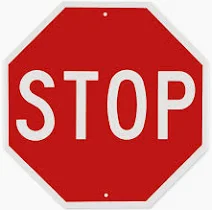

Below we give possible solutions. Don't let us spoil your fun.

## Possible Solutions

**Goal count.** Count the goal facts that do not hold yet. Each of them needs at least one action, but a single action might achieve several of them at once, so in general this heuristic is not admissible. For goals made only of `on` facts, i.e., grounded `on` predicates like `(on b1 b2)`, `(on b7 b5)`, `(on green blue)`, it is: every blocks world action changes at most one `on` fact.

In [ ]:
def goal_count_heuristic(state, problem):
    return sum(1 for atom in goal_atoms(problem) if not state.get_value(atom).is_true())


plan, stats = a_star(problem, goal_count_heuristic)
print_results("A* with goal-count heuristic", plan, stats)

**Delete relaxation.** Here we exploit the relaxed version of the problem. In the relaxed problem, actions only add facts and never delete them, so applying an action can only make more actions applicable. We apply *all* applicable actions at once, layer after layer, until all goal facts have been reached. The number of layers is our estimate.

To do this we need the *grounded* actions, i.e., all the actions with all combinations of concrete parameters. UPF can compute them for us:

In [ ]:
from unified_planning.engines import CompilationKind
from unified_planning.shortcuts import Compiler

_relaxed_cache = {}


def relaxed_actions(problem):
    """A list of (preconditions, add effects) pairs, one per grounded action, as sets of facts."""
    if id(problem) not in _relaxed_cache:
        with Compiler(problem_kind=problem.kind, compilation_kind=CompilationKind.GROUNDING) as grounder:
            grounded = grounder.compile(problem).problem

        actions = []
        for action in grounded.actions:
            preconditions = set()
            for precondition in action.preconditions:
                preconditions.update(atom for atom in (precondition.args if precondition.is_and() else [precondition]) if not atom.is_not())
            add_effects = {effect.fluent for effect in action.effects if effect.value.is_true()}
            actions.append((preconditions, add_effects))
        _relaxed_cache[id(problem)] = actions
    return _relaxed_cache[id(problem)]


def relaxed_layers_heuristic(state, problem):
    goals = set(goal_atoms(problem))
    facts = true_facts(state, problem)
    n_layers = 0
    while not goals <= facts:
        new_facts = set()
        for preconditions, add_effects in relaxed_actions(problem):
            if preconditions <= facts:
                new_facts |= add_effects
        if new_facts <= facts:
            return math.inf  # even the relaxed problem is unsolvable from here
        facts |= new_facts
        n_layers += 1
    return n_layers


plan, stats = a_star(problem, relaxed_layers_heuristic)
print_results("A* with relaxed-layers heuristic", plan, stats)

❓ How did you do? Was your approach able to expand fewer nodes? Did it take less time?

Note that some heuristics might reduce the number of explored nodes, but may be expensive to compute, and vice-versa. This trade-off between an informative heuristic and one that is easier to compute is at the heart of planning research. (The relaxed-layers heuristic above is known as $h^{max}$. It is admissible, but as you saw, not very informative. The closely related $h^{FF}$ heuristic extracts an actual relaxed plan from the layers and counts its actions. It is not admissible, but it is much more informative.)

⚒ **Task 2.1**: compare heuristics on a harder problem.

To better understand the effectiveness of different heuristics, let's compare them using a more complex problem. Below is a problem instance with 6 blocks that requires multiple stacking and unstacking actions. Run BFS, A* with the goal-count heuristic, A* with the relaxed-layers heuristic and greedy best-first search with the relaxed-layers heuristic on it, and compare plan lengths, expanded nodes and running times.

Then, write an even harder problem of your own (add a block or two, or make the goal a full tower) and see which searches can still solve it in reasonable time.

In [ ]:
HARD_PROBLEM = """
(define (problem blocks-6)
    (:domain blocks)
    (:objects a b c d e f - block rob - robot)
    (:init
        (ontable c) (on d c) (on f d) (on e f) (clear e)
        (ontable a) (clear a)
        (ontable b) (clear b)
        (handempty rob)
    )
    (:goal (and (on b e) (on c b) (on f c)))
)
"""

hard_problem = PDDLReader().parse_problem_string(DOMAIN, HARD_PROBLEM)

### Your code here, use as many cells as you want.

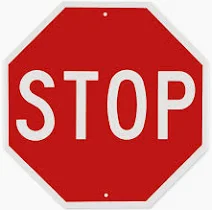

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
SEARCHES = {
    "BFS": breadth_first_search,
    "A* with goal-count": lambda problem, **kwargs: a_star(problem, goal_count_heuristic, **kwargs),
    "A* with relaxed-layers": lambda problem, **kwargs: a_star(problem, relaxed_layers_heuristic, **kwargs),
    "GBFS with relaxed-layers": lambda problem, **kwargs: greedy_best_first_search(problem, relaxed_layers_heuristic, **kwargs),
}


def compare_searches(problem, **kwargs):
    for name, search in SEARCHES.items():
        plan, stats = search(problem, **kwargs)
        length = "-" if plan is None else len(plan)
        print(f"{name:<25} plan length: {length:>3}   expanded: {stats['expanded']:>6}   time: {stats['time']:6.2f}s")


compare_searches(hard_problem)

All four searches find a 12-action plan, but they differ a lot in effort. The goal-count heuristic halves the number of expanded nodes compared to BFS, and the relaxed-layers heuristic halves it again, although each of its evaluations is more expensive, so the running time barely improves over goal count. Greedy best-first search expands only about a hundred nodes and is by far the fastest, and here it happens to find an optimal plan as well.

For a harder problem, we add a block and ask for a single tower of all seven blocks. To keep the running time reasonable, we cap every search at 10,000 expansions (a search that hits the cap reports no plan).

In [ ]:
HARDER_PROBLEM = """
(define (problem blocks-7)
    (:domain blocks)
    (:objects a b c d e f g - block rob - robot)
    (:init
        (ontable c) (on d c) (on f d) (on e f) (clear e)
        (ontable a) (on g a) (clear g)
        (ontable b) (clear b)
        (handempty rob)
    )
    (:goal (and (on a b) (on b c) (on c d) (on d e) (on e f) (on f g)))
)
"""

harder_problem = PDDLReader().parse_problem_string(DOMAIN, HARDER_PROBLEM)
compare_searches(harder_problem, max_expansions=10_000)

BFS and A* with the relaxed-layers heuristic run out of expansions. A* with goal count finds an optimal 16-action plan: with six goal facts, counting the unachieved ones is much more informative than the number of relaxed layers, which only reflects the hardest single goal fact. Greedy best-first search finds a plan after a few hundred expansions, but it is 20 actions long. Giving up optimality buys a lot of speed, a trade-off we will meet again with Fast Downward below.

## Heuristics in a state-of-the-art planner

Our search works for 4 or 5 blocks, but not much beyond that, because the states are Python objects, the successor generation goes through the simulator, and our heuristics recompute everything from scratch. Fast Downward does the same things much more efficiently. It compiles the problem into a compact representation, computes heuristics such as $h^{FF}$ incrementally, and comes with many search algorithms and heuristics.

UPF lets us choose among them by passing a Fast Downward *search configuration*. Let's compare a few on a problem that is out of reach for our own search: 7 blocks that must be rearranged into a single tower. We read the number of expanded states from the planner's log.

In [ ]:
BIG_PROBLEM = """
(define (problem blocks-7)
    (:domain blocks)
    (:objects a b c d e f g - block rob - robot)
    (:init
        (ontable f) (on g f) (on a g) (on d a) (on c d) (clear c)
        (ontable e) (on b e) (clear b)
        (handempty rob)
    )
    (:goal (and (on g d) (on c g) (on a c) (on e a) (on f e) (on b f)))
)
"""

big_problem = PDDLReader().parse_problem_string(DOMAIN, BIG_PROBLEM)

In [ ]:
import re

SEARCH_CONFIGS = {
    "A* with the blind heuristic (h=0, i.e., BFS)": "astar(blind())",
    "A* with LM-cut (admissible)": "astar(lmcut())",
    "greedy best-first search with FF (inadmissible)": "eager_greedy([ff()])",
    "lazy greedy best-first search with FF and preferred operators (Fast Downward's default)": "lazy_greedy([ff()],preferred=[ff()])",
}


def solve_with_fast_downward(problem, search_config):
    with OneshotPlanner(name="fast-downward", params={"fast_downward_search_config": search_config}) as planner:
        result = planner.solve(problem, output_stream=None)
    log = "\n".join(message.message for message in result.log_messages)
    match = re.search(r"Expanded (\d+) state", log)
    n_expanded = int(match.group(1)) if match else None
    return result, n_expanded


for name, config in SEARCH_CONFIGS.items():
    result, n_expanded = solve_with_fast_downward(big_problem, config)
    print(f"{name}:\n    plan length {len(result.plan.actions)}, expanded states {n_expanded}")

❓ **Which configurations found the shortest plan? Which expanded the fewest states? Why would anyone use an inadmissible heuristic?**

(If you are curious about the other options, the [Fast Downward documentation](https://www.fast-downward.org/latest/search/) lists all the search algorithms and heuristics.)

### Optimality

Fast Downward's default configuration is *satisficing*: it aims to find *a* valid plan quickly rather than the best one. When we need an optimal plan we could pick an admissible configuration ourselves, as we did above, but UPF can do this for us. Every problem has a `kind` property that captures the features it uses:

In [ ]:
print(problem.kind)

Given the problem kind and the guarantees we require, UPF selects a suitable engine among the installed ones. Asking for an optimality guarantee makes it choose Fast Downward's optimal configuration (A* with LM-cut, also available directly as the `fast-downward-opt` engine):

In [ ]:
from unified_planning.engines import PlanGenerationResultStatus

with OneshotPlanner(problem_kind=big_problem.kind, optimality_guarantee=PlanGenerationResultStatus.SOLVED_OPTIMALLY) as planner:
    print("selected engine:", planner.name)
    result = planner.solve(big_problem)

print("plan length:", len(result.plan.actions))

# Simulating Plans with PDDLGym

So far, a plan is just a list of strings. In the rest of the workshop, plans will be executed by a (simulated) robot, and things will go wrong along the way. As a first step, let's execute our plans in [PDDLGym](https://github.com/tomsilver/pddlgym), a simulator that is no more detailed than the PDDL model itself.

PDDLGym turns PDDL problems into [Gym](https://github.com/openai/gym) environments. Gym (now superseded by [gymnasium](https://gymnasium.farama.org/index.html)) is a toolkit for decision-making environments, best known from reinforcement learning research, that defines a standard interface: `reset()` brings the environment to an initial state and returns the initial observation, and `step(action)` applies an action and returns the next observation. PDDLGym already implements many classic planning domains, blocks world included, and some of them come with a visualizer.

The collapsed cell below contains a few helpers for displaying PDDLGym states and for converting between PDDLGym and UPF. Run it, but there is no need to read it.

In [ ]:
#@title Helper: PDDLGym visualization and PDDLGym ⇄ Unified Planning conversion { display-mode: "form" }
import contextlib
import io
import warnings

import matplotlib.pyplot as plt
import mediapy as media

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import pddlgym  # the (unmaintained) gym package prints a long deprecation notice; keep it quiet
import pddlgym.rendering.blocks as blocks_rendering
from pddlgym.structs import Type

# PDDLGym names some objects the same as their types (e.g. "robot - robot"). UPF complains about this by default.
get_environment().error_used_name = False
warnings.filterwarnings("ignore", message="Name .* already defined")


def render_blocks(env):
    """Render the current state of a PDDLGym blocks world environment as an RGB image, with block names."""
    original_draw_blocks = blocks_rendering.draw_blocks

    def draw_blocks_with_names(ax, block_width, block_height, block_positions):
        original_draw_blocks(ax, block_width, block_height, block_positions)
        for block, (x, y) in block_positions.items():
            ax.text(x + block_width / 2, y + block_height / 2, block.name, ha="center", va="center", fontsize=10)

    blocks_rendering.draw_blocks = draw_blocks_with_names
    try:
        frame = env.render()[:, :, :3]  # drop the alpha channel
    finally:
        blocks_rendering.draw_blocks = original_draw_blocks
        plt.close("all")  # the renderer creates matplotlib figures; do not let them show up inline
    return frame


def show_blocks(env):
    media.show_image(render_blocks(env), height=320)


def _strip_pddlgym_action_literals(pddl_text, action_names):
    """PDDLGym adds every action also as a predicate/literal. Remove those lines, they are not part of the model."""
    return "\n".join(
        line for line in pddl_text.splitlines()
        if not any(line.strip().startswith(f"({name} ") or line.strip() == f"({name})" for name in action_names)
    )


def pddlgym_to_up_problem(env, debug_info):
    """Convert the PDDLGym environment's current problem (whose files are listed in the debug info returned by reset) to a unified_planning Problem."""
    action_names = [predicate.name for predicate in env.action_space.predicates]
    with open(debug_info["domain_file"]) as f:
        domain_text = _strip_pddlgym_action_literals(f.read(), action_names)
    with open(debug_info["problem_file"]) as f:
        problem_text = _strip_pddlgym_action_literals(f.read(), action_names)
    return PDDLReader().parse_problem_string(domain_text, problem_text)


def up_action_to_pddlgym(action_instance, env):
    """Map a unified_planning action instance to the PDDLGym literal that triggers the same action."""
    up_name = action_instance.action.name.replace("-", "").lower()
    predicate = next(p for p in env.action_space.predicates if p.name.replace("-", "").lower() == up_name)
    # PDDLGym action literals mention only some of the action's parameters (e.g. the robot is implicit),
    # so we match them by type, in order.
    variables = []
    remaining = list(action_instance.actual_parameters)
    for var_type in predicate.var_types:
        param = next(p for p in remaining if p.type.name == str(var_type))
        remaining.remove(param)
        variables.append(Type(str(var_type))(param.object().name))
    return predicate(*variables)


def run_plan_in_pddlgym(env, plan):
    """Execute a unified_planning plan in the PDDLGym environment. Returns the rendered frames and whether the goal was reached."""
    frames = [render_blocks(env)]
    done = False
    for action_instance in plan.actions:
        observation, reward, done, truncated, info = env.step(up_action_to_pddlgym(action_instance, env))
        frames.append(render_blocks(env))
    return frames, done

In [ ]:
import pddlgym

env = pddlgym.make("PDDLEnvBlocks-v0")
env.fix_problem_index(4)  # PDDLGym ships several problem instances; select a specific one for now
observation, debug_info = env.reset()
debug_info

As we can see, the environment is initialized from `.pddl` files, similar to the ones we wrote ourselves. The observation is the set of true facts, which is a *state* as we defined it above:

In [ ]:
observation

Reading a state is much easier from a picture. PDDLGym's blocks world visualizer draws the blocks and the robot's hand (we add the block names on top of the blocks):

In [ ]:
show_blocks(env)

Let's take a random action and see how the state changes. Gym environments expose an *action space* that knows which actions exist; PDDLGym can also sample only from those that are applicable in the current state.

In [ ]:
action = env.action_space.sample(observation)
print("applying action:", action)

observation, reward, done, truncated, debug_info = env.step(action)
show_blocks(env)

## Executing a plan

Now let's plan for this environment. Its domain is the blocks world we already know (with a bit of PDDLGym-specific bookkeeping that the helper cell strips away), and the helper `pddlgym_to_up_problem` reads the files listed in the debug info and turns them into a UPF problem. Working with different tools often requires translating between their representations. This is not the most interesting part of the work, but we will need similar translations when we connect a planner to a robot.

In [ ]:
observation, debug_info = env.reset()  # back to the initial state (the problem index is fixed, so it is the same problem)
gym_problem = pddlgym_to_up_problem(env, debug_info)

with OneshotPlanner(name="fast-downward") as planner:
    result = planner.solve(gym_problem)

for action in result.plan.actions:
    print(action)

`run_plan_in_pddlgym` converts each action of the plan into a PDDLGym action, steps the environment, and records a frame after every step. Let's watch the plan unfold:

In [ ]:
frames, done = run_plan_in_pddlgym(env, result.plan)

print("goal reached:", done)
media.show_video(frames, fps=2, height=320)

❓ **Watch the video again. Does the plan contain any redundant moves? Which planner configuration did we use?**

⚒ **Task 3**: Solve the same problem with an optimality guarantee (see the previous section), execute the plan, and compare the two videos. Is the difference what you expected?

In [ ]:
env.reset()
# your code here

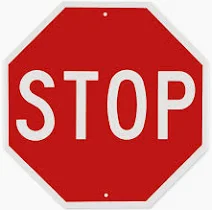

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
env.reset()

with OneshotPlanner(problem_kind=gym_problem.kind, optimality_guarantee=PlanGenerationResultStatus.SOLVED_OPTIMALLY) as planner:
    print("selected engine:", planner.name)
    optimal_result = planner.solve(gym_problem)

print("satisficing plan length:", len(result.plan.actions))
print("optimal plan length:    ", len(optimal_result.plan.actions))

frames, done = run_plan_in_pddlgym(env, optimal_result.plan)

print("goal reached:", done)
media.show_video(frames, fps=2, height=320)

The optimal plan is 4 actions shorter. The satisficing plan stacks `b` on `c` early on, only to unstack it and put it back on the table later, while the optimal plan first clears all the blocks it needs and then builds the tower bottom-up. Fast Downward's default configuration (lazy greedy search with $h^{FF}$) rushes toward goal facts that look achievable, and is happy with the first plan it finds.

## One pipeline, many problems

Our planner is general. Nothing in the pipeline above was specific to the problem instance, or even to blocks world. Let's wrap the pipeline in a function and use it to solve several random problems that PDDLGym provides, verifying each time that we reach the goal.

In [ ]:
def solve_and_show(env, optimal=False):
    observation, debug_info = env.reset()
    problem = pddlgym_to_up_problem(env, debug_info)

    if optimal:
        planner = OneshotPlanner(problem_kind=problem.kind, optimality_guarantee=PlanGenerationResultStatus.SOLVED_OPTIMALLY)
    else:
        planner = OneshotPlanner(name="fast-downward")
    with planner:
        result = planner.solve(problem)

    frames, done = run_plan_in_pddlgym(env, result.plan)
    print(f"{debug_info['problem_file'].split('/')[-1]}: plan length {len(result.plan.actions)}, goal reached: {done}")
    media.show_video(frames, fps=2, height=240)


env = pddlgym.make("PDDLEnvBlocks-v0")  # a new environment without a fixed problem index: reset() picks a random problem

for _ in range(3):
    solve_and_show(env)

❓ **Can we use this pipeline to solve other domains?**

In theory, yes: Fast Downward can solve all the domains that ship with PDDLGym, and UPF does not care which domain it reads. In practice, each PDDLGym domain has its own quirks in how actions are represented, so the conversion helpers would need to be adapted for each. In robotics, this kind of adaptation is common when switching between robot platforms and environments. Even though we abstracted away the physical robot entirely, we already ran into this problem here.

# Extending Blocks World: the N-Table Blocks World

There are many ways to extend the basic setting, each introducing its own form of complexity. With our wish to focus on challenges for robotic agents, we present an extension of BW to multi-table settings, in which blocks are distributed between $n$ surfaces (i.e., tables). The goal specification considers a configuration of blocks for a subset of tables. This **N-Table Blocks World (NTBW)** will accompany us throughout the workshop, and later on we will meet it in a physics simulator with a real robot arm model.

![NTBW](https://raw.githubusercontent.com/CLAIR-LAB-TECHNION/ICAPS-24/main/assets/figures/n_table_genAI.png)

❓ **What are the key changes from the basic setting that need to be considered here?**

There are many ways to model this setting with PDDL. One option is given below, where we add the table as a parameter to the relevant predicates and actions, and give every block a color.

In [ ]:
NTBW_DOMAIN = """
(define (domain n-table-blocks-world)
  (:requirements :strips :typing)
  (:types block color table)
  (:predicates (on ?b1 ?b2 - block)
               (ontable ?b - block ?t - table)
               (clear ?b - block)
               (handempty)
               (holding ?b - block)
               (bcolor ?b - block ?c - color))

  (:action pick-up
     :parameters (?b - block ?t - table)
     :precondition (and (clear ?b) (ontable ?b ?t) (handempty))
     :effect (and (not (ontable ?b ?t)) (not (clear ?b)) (not (handempty)) (holding ?b)))

  (:action put-down
     :parameters (?b - block ?t - table)
     :precondition (holding ?b)
     :effect (and (not (holding ?b)) (clear ?b) (handempty) (ontable ?b ?t)))

  (:action stack
     :parameters (?b1 ?b2 - block)
     :precondition (and (holding ?b1) (clear ?b2))
     :effect (and (not (holding ?b1)) (not (clear ?b2)) (clear ?b1) (handempty) (on ?b1 ?b2)))

  (:action unstack
     :parameters (?b1 ?b2 - block)
     :precondition (and (on ?b1 ?b2) (clear ?b1) (handempty))
     :effect (and (holding ?b1) (clear ?b2) (not (clear ?b1)) (not (handempty)) (not (on ?b1 ?b2))))
)
"""

NTBW_PROBLEM = """
(define (problem ntbw-3t5b)
  (:domain n-table-blocks-world)
  (:objects
    b1 b2 b3 b4 b5 - block
    yellow blue green red - color
    t1 t2 t3 - table)
  (:init
    (handempty)
    (ontable b1 t1) (bcolor b1 yellow)
    (on b2 b1) (clear b2) (bcolor b2 blue)
    (ontable b3 t2) (clear b3) (bcolor b3 yellow)
    (ontable b4 t3) (clear b4) (bcolor b4 green)
    (ontable b5 t3) (clear b5) (bcolor b5 red))
  (:goal (and (on b3 b1)))
)
"""

ntbw_problem = PDDLReader().parse_problem_string(NTBW_DOMAIN, NTBW_PROBLEM)

with OneshotPlanner(name="fast-downward") as planner:
    result = planner.solve(ntbw_problem)

for action in result.plan.actions:
    print(action)

❓ **What aspects of the problem were ignored in this formulation?**

In a more advanced (and perhaps more realistic) version of NTBW, one may require an optimal plan to achieve a configuration of blocks of certain *colors* (e.g., two yellow blocks on top of a blue block, or a yellow block on table 1) while being agnostic as to which blocks are used. This requires reasoning at a higher level of abstraction, highlighting even further the need to combine task and motion planning.

In addition to the need to find feasible motions that achieve the high-level action, we should also start thinking about the kind of low-level information that needs to be somehow reflected in the high-level representation of the problem.
For example, in the image of our NTBW setting above, picking up a yellow block from each table achieves the same predicate of a yellow block being grasped by the gripper, but these actions have very different costs, and possibly risks, associated with them. How do we capture this in the high-level plans?

We don't need to give a complete answer to this yet, but it would be great to start thinking about this as we progress with the tutorials.

⚒ **Task 4**:

1. Try to capture some of the complexities that would occur in a real-world NTBW that are not captured in the PDDL model we gave above.

2. As another challenge, can you think of a representation that will allow specifying that there should be a block with a specified color on a table, instead of referring to labeled blocks (e.g., "a yellow block on table 1")?

The `:requirements` you may find useful include `:negative-preconditions`, `:equality`, `:conditional-effects`, `:existential-preconditions` and `:action-costs`. Fast Downward supports all of them (the [PDDL reference](https://planning.wiki/ref/pddl/requirements) is a good place to look them up). If you get stuck on syntax, the [planning.domains editor](https://editor.planning.domains/) is a nice place to experiment.

In [ ]:
NTBW_DOMAIN_EXTENDED = NTBW_DOMAIN  # your code here: replace with your own domain string
NTBW_PROBLEM_EXTENDED = NTBW_PROBLEM  # your code here: replace with your own problem string

You can create the extended problem and solve it as follows.

In [ ]:
extended_problem = PDDLReader().parse_problem_string(NTBW_DOMAIN_EXTENDED, NTBW_PROBLEM_EXTENDED)

with OneshotPlanner(problem_kind=extended_problem.kind) as planner:
    print("selected engine:", planner.name)
    result = planner.solve(extended_problem)

print("status:", result.status.name)
for action in result.plan.actions:
    print(action)

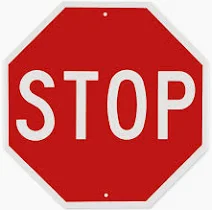

Below we give possible solutions. Don't let us spoil your fun.

## Possible Solutions

**Color-based goals.** One way to say "a yellow block on table 1" without naming a block is to *derive* it: we add a predicate `(color-on-table ?c ?t)` and update it whenever a block is put down on a table. With this domain, the goal is simply `(color-on-table yellow t1)`.

Note that this is not a solid solution: if the yellow block is picked up again, the predicate is not reset (fixing this requires knowing whether *another* yellow block is still on the table, which is where `:existential-preconditions` or `:conditional-effects` come in handy).

In [ ]:
NTBW_DOMAIN_COLORS = """
(define (domain n-table-blocks-world)
  (:requirements :strips :typing)
  (:types block color table)
  (:predicates (on ?b1 ?b2 - block)
               (ontable ?b - block ?t - table)
               (clear ?b - block)
               (handempty)
               (holding ?b - block)
               (bcolor ?b - block ?c - color)
               (color-on-table ?c - color ?t - table))

  (:action pick-up
     :parameters (?b - block ?t - table)
     :precondition (and (clear ?b) (ontable ?b ?t) (handempty))
     :effect (and (not (ontable ?b ?t)) (not (clear ?b)) (not (handempty)) (holding ?b)))

  (:action put-down
     :parameters (?b - block ?t - table ?c - color)
     :precondition (and (holding ?b) (bcolor ?b ?c))
     :effect (and (not (holding ?b)) (clear ?b) (handempty) (ontable ?b ?t) (color-on-table ?c ?t)))

  (:action stack
     :parameters (?b1 ?b2 - block)
     :precondition (and (holding ?b1) (clear ?b2))
     :effect (and (not (holding ?b1)) (not (clear ?b2)) (clear ?b1) (handempty) (on ?b1 ?b2)))

  (:action unstack
     :parameters (?b1 ?b2 - block)
     :precondition (and (on ?b1 ?b2) (clear ?b1) (handempty))
     :effect (and (holding ?b1) (clear ?b2) (not (clear ?b1)) (not (handempty)) (not (on ?b1 ?b2))))
)
"""

NTBW_PROBLEM_COLORS = """
(define (problem ntbw-colors)
  (:domain n-table-blocks-world)
  (:objects
    b1 b2 b3 b4 b5 - block
    yellow blue green red - color
    t1 t2 t3 - table)
  (:init
    (handempty)
    (ontable b1 t1) (clear b1) (bcolor b1 blue)
    (ontable b2 t2) (clear b2) (bcolor b2 blue)
    (ontable b3 t2) (bcolor b3 yellow)
    (on b4 b3) (clear b4) (bcolor b4 green)
    (ontable b5 t3) (clear b5) (bcolor b5 yellow))
  (:goal (and (color-on-table yellow t1)))
)
"""

colors_problem = PDDLReader().parse_problem_string(NTBW_DOMAIN_COLORS, NTBW_PROBLEM_COLORS)

with OneshotPlanner(name="fast-downward") as planner:
    result = planner.solve(colors_problem)

for action in result.plan.actions:
    print(action)

The planner is free to use *either* yellow block, and it is up to the search to pick the convenient one (here, `b5` is clear while `b3` is buried under `b4`).

**Action costs.** In the formulation above, all actions cost the same. Actual costs are not at all uniform (and loyally estimating them is part of what makes integrated task and motion planning challenging). PDDL lets us attach a cost to every action with `:action-costs`. Below, the robot must explicitly *move* between tables, and moving costs the distance between the tables. The metric at the end of the problem tells the planner to minimize the total cost.

In [ ]:
NTBW_DOMAIN_COSTS = """
(define (domain n-table-blocks-world)
  (:requirements :strips :typing :action-costs)
  (:types block color table)
  (:predicates (on ?b1 ?b2 - block)
               (ontable ?b - block ?t - table)
               (clear ?b - block)
               (handempty)
               (holding ?b - block)
               (bcolor ?b - block ?c - color)
               (color-on-table ?c - color ?t - table)
               (robot-at ?t - table))
  (:functions (total-cost) - number
              (table-distance ?t1 ?t2 - table) - number)

  (:action move
     :parameters (?from ?to - table)
     :precondition (robot-at ?from)
     :effect (and (not (robot-at ?from)) (robot-at ?to) (increase (total-cost) (table-distance ?from ?to))))

  (:action pick-up
     :parameters (?b - block ?t - table)
     :precondition (and (clear ?b) (ontable ?b ?t) (handempty) (robot-at ?t))
     :effect (and (not (ontable ?b ?t)) (not (clear ?b)) (not (handempty)) (holding ?b) (increase (total-cost) 8)))

  (:action put-down
     :parameters (?b - block ?t - table ?c - color)
     :precondition (and (holding ?b) (bcolor ?b ?c) (robot-at ?t))
     :effect (and (not (holding ?b)) (clear ?b) (handempty) (ontable ?b ?t) (color-on-table ?c ?t) (increase (total-cost) 5)))

  (:action stack
     :parameters (?b1 ?b2 - block ?t - table)
     :precondition (and (holding ?b1) (clear ?b2) (ontable ?b2 ?t) (robot-at ?t))
     :effect (and (not (holding ?b1)) (not (clear ?b2)) (clear ?b1) (handempty) (on ?b1 ?b2) (increase (total-cost) 5)))

  (:action unstack
     :parameters (?b1 ?b2 - block ?t - table)
     :precondition (and (on ?b1 ?b2) (clear ?b1) (handempty) (ontable ?b2 ?t) (robot-at ?t))
     :effect (and (holding ?b1) (clear ?b2) (not (clear ?b1)) (not (handempty)) (not (on ?b1 ?b2)) (increase (total-cost) 8)))
)
"""

NTBW_PROBLEM_COSTS = """
(define (problem ntbw-costs)
  (:domain n-table-blocks-world)
  (:objects
    b1 b2 b3 b4 b5 - block
    yellow blue green red - color
    t1 t2 t3 - table)
  (:init
    (handempty)
    (robot-at t1)
    (ontable b1 t1) (clear b1) (bcolor b1 blue)
    (ontable b2 t2) (clear b2) (bcolor b2 blue)
    (ontable b3 t2) (bcolor b3 yellow)
    (on b4 b3) (clear b4) (bcolor b4 green)
    (ontable b5 t3) (clear b5) (bcolor b5 yellow)
    (= (total-cost) 0)
    (= (table-distance t1 t2) 1) (= (table-distance t2 t1) 1)
    (= (table-distance t2 t3) 10) (= (table-distance t3 t2) 10)
    (= (table-distance t1 t3) 11) (= (table-distance t3 t1) 11)
    (= (table-distance t1 t1) 0) (= (table-distance t2 t2) 0) (= (table-distance t3 t3) 0))
  (:goal (and (color-on-table yellow t1)))
  (:metric minimize (total-cost))
)
"""

costs_problem = PDDLReader().parse_problem_string(NTBW_DOMAIN_COSTS, NTBW_PROBLEM_COSTS)
print(costs_problem.kind)

The problem kind now includes a quality metric. Note the `REAL_NUMBERS_IN_ACTIONS_COST` feature: UPF's PDDL reader types every numeric fluent as a real number, while Fast Downward officially supports only integer costs, so UPF would refuse to pair the two. Since all our numbers are in fact integers, we ask for the optimal Fast Downward engine explicitly and tell UPF to skip its compatibility check.

In [ ]:
def plan_cost(problem, plan):
    """Sum the action costs of a plan according to the problem's (single) quality metric."""
    metric = problem.quality_metrics[0]
    expression_manager = get_environment().expression_manager
    total = 0
    with SequentialSimulator(problem) as simulator:
        state = simulator.get_initial_state()
        for action_instance in plan.actions:
            cost = metric.get_action_cost(action_instance.action)
            # plug the actual parameters into the cost expression, e.g. table-distance(?from, ?to) -> table-distance(t1, t2)
            cost = cost.substitute({expression_manager.ParameterExp(p): v for p, v in zip(action_instance.action.parameters, action_instance.actual_parameters)})
            total += state.get_value(cost).constant_value() if cost.is_fluent_exp() else cost.constant_value()
            state = simulator.apply(state, action_instance)
    return total


with OneshotPlanner(name="fast-downward-opt") as planner:
    planner.skip_checks = True
    result = planner.solve(costs_problem)

print("status:", result.status.name)
print("plan cost:", plan_cost(costs_problem, result.plan))
for action in result.plan.actions:
    print(action)

With table 3 far away, the planner now prefers to dig out `b3` from under `b4` on the nearby table 2 (cost 28) over the long trip to fetch `b5` (cost 35). Make table 3 closer (e.g., set the distances between tables 2 and 3 and between tables 1 and 3 to 1 and 2) and re-run to see the planner choose a different plan.

❓ **Are we done? Is there a way to account for the other complexities you thought of in Task 4?**

# Task Planning in the real(istic) world

So far, we used a high-level abstraction of the blocks world setting. For example, we used a "pick up block b2 from table t3" action which we could apply (deterministically) and use the outcome for further exploring our state space.

In order to use the plans generated by the abstract representation, we need to understand how they relate to a real robotic setting. This means we can't simply assume a pick-up action will be *executed* as expected, we need to **ground** the representation within the setting of interest.

Note that the grounding here is related to but different from the grounding we did for PDDL elements. In PDDL, grounding is the process of converting a domain and problem description into a fully instantiated representation, where all variables, objects, predicates, and actions are explicitly defined. For example, we take the action `pick-up (?b - block ?t - table)` and ground it to block `b2` and table `t3` from our problem description, resulting in the grounded action `pick-up (b2, t3)`.

In robotics, grounding high-level actions to actions that can be performed in the real-world (or simulated) setting involves translating abstract actions into concrete low-level commands or motions that the robot's actuators can execute. This process is crucial for enabling robots to autonomously perform tasks specified at a higher level, such as manipulation, navigation, or interaction with the environment. In order to understand this, we need to know a little more about robots.

## What's a robot?

![agent-env.png](https://raw.githubusercontent.com/CLAIR-LAB-TECHNION/ICAPS-24/main/assets/figures/agent-env.png)

We can't, of course, give you a simple and widely-acceptable definition, so we won't even try. We can say that a robotic agent typically consists of several components that work together to perceive, reason, and act in the environment. We therefore generally describe a robot as an agent with three main components:

* **Perception:** the process of interpreting sensor data to understand the robot's environment. Robots use various sensors to perceive the environment, including cameras, depth sensors, and possibly tactile sensors for touching and grasping objects. These sensors provide information about the current state of the environment, including the positions of the agent and of objects in its environment. Perception may involve different tasks such as object detection and recognition, scene understanding, localization (determining the robot's position), mapping (building a representation of the environment), and sensor fusion (integrating data from multiple sensors to obtain a coherent perception of the environment).

* **Actuation:** Actuators are the physical components responsible for executing the actions by translating control commands into physical motion. The robot needs actuators to manipulate objects in the environment. This might include robotic arms with grippers or other end-effectors capable of picking up, moving, and placing blocks. At a lower level, actuators include motors, servos, pneumatic actuators, and hydraulic actuators. Actuators allow the robot to perform physical actions such as moving its limbs, grasping objects, or locomoting through its environment.

* **Control:** The control system is responsible for processing sensory input and generating appropriate actions for the robot to take, i.e., generating commands to actuate the robot's actuators (e.g., motors, joints), ensuring that it interacts with its environment in desired ways.
One aspect of control can involve high-level reasoning such as task planning (generating a sequence of actions to achieve a goal), path planning (finding a collision-free path from the robot's current position to a desired position), and decision-making under uncertainty (making decisions in situations with incomplete or uncertain information). Another aspect involves low-level control tasks such as trajectory generation, feedback control (adjusting the robot's actions based on sensor feedback), and motion execution.

Naturally, our focus here is on the control component since we are interested in planning and decision-making.
Traditionally, most robots were not equipped with reasoning capabilities, and their behaviors (i.e., policies) were mostly predetermined and fixed.

There are two main paradigms for enabling autonomy in robotic agents, each with its advantages, limitations, and applications.

**Model-based** approaches rely on an explicit model of the dynamics of the robot and its environment, i.e., a description of how the state changes in response to the robot's actions. The agent uses this model to predict the outcomes of its actions and to plan or optimize its behavior before (or while) acting. Importantly, "model-based" does not mean "hand-crafted". The model may be derived analytically from principles of physics and mechanics (e.g., equations that govern the robot's motion and its interactions with objects), but it may also be learned from data, for example via system identification or by training a neural network to predict the next state from the current state and action. Either way, having a model provides a clear understanding of how the robot is expected to behave, makes it possible to plan for new goals without additional training, and tends to be sample-efficient. On the other hand, model-based approaches are sensitive to modeling errors. Inaccuracies in the model (whether hand-crafted or learned) may compound over long planning horizons and lead to poor behavior in the real world. Moreover, building and planning with complex models can be computationally intensive, especially for systems with high degrees of freedom or non-linear dynamics.

In contrast, **model-free** approaches do not build or use a model of the dynamics. Instead, they learn a policy (a mapping from observations to actions) or a value function directly from experience, without ever explicitly predicting what the next state will be. This is typically done via reinforcement learning (learning from trial-and-error interaction with the environment) or imitation learning (learning to mimic demonstrations, e.g., from a human teleoperating the robot). Since no model is required, these approaches can act in and adapt to complex environments for which the dynamics are hard to model, and they avoid the problem of compounding model errors. On the other hand, most model-free approaches require large amounts of interaction or demonstration data, which may be challenging and expensive to collect in robotic settings. Large-scale data is often collected via simulation, but we must remember that a simulator is essentially a model of the environment. In addition, the resulting policies are tied to the task they were trained on, often struggle to generalize to new or unseen scenarios, and can be difficult to interpret due to their opaque nature.

### Planning for robots

Our focus here is on using planning for the control of robotic agents. In order to use the plans generated by the abstract representations we have been using above, we need to understand how they relate to a real robotic setting. This means we can't simply assume a pick-up action will happen as expected, we need to ground it within the setting of interest and translate it into a sequence of motions that are achievable in the physical setting and that achieve the desired goal.

For example, let's see what we need to consider if we want our robot to perform the action **`pick-up (b2, t3)`**.

In our example, picking up a block that is in a stable position on a surface involves bringing the robot to a position, known in robotics as a **configuration**, from which if the gripper is closed, the block is caught between its two fingers without slipping. This may sound easy, but it's not that simple.

First, we need to compute a configuration from which a grasp should be performed. This depends on the robot's capabilities (which configurations can it reach?), on the object being manipulated (is it rigid or deformable?), and on the ability to sense the environment and accurately estimate the current state.

In our example, this involves:

* Detecting the position of table `t3`.
* Detecting the position of `b2`. If there are several blocks on `t3`, but each with a unique color, and the robot has an RGB camera, it might be sufficient to look for "blue". However, if we have multiple blue blocks, we would need to monitor the position of each object.
* Finding a good grasp configuration from which to attempt a grasp, i.e., from which to close the gripper. If we fail, we might move the object (or even drop it).
* Finding a way to get the robot safely from its current configuration to the chosen grasp configuration (typically referred to as motion planning).

Planning for robots involves continuously analyzing the current state of the environment, determining which actions are possible, and selecting an appropriate sequence of actions that will achieve the goal.

Another complication that arises when planning for robots is the fact that they often act in highly uncertain environments, and challenges such as sensor noise, uncertainty in perception, variability in object properties, and the complexity of robot manipulation need to be addressed. Thus, even after a plan has been selected, there is a need to process incoming sensory information and control and monitor the robot's actuators to perform the intended actions.
This often involves combining algorithms for perception, planning, and control, as well as careful integration of hardware and software components to ensure reliable operation. Also, if the robot fails to execute its prescribed actions or encounters unexpected obstacles or changes in the environment, it may need to adapt its plan on the fly to achieve the goal despite the new circumstances.

There are of course many other factors that need to be considered, such as safety, communication, and interaction with other agents and with humans, and many more which we can't cover here, but we encourage you to explore.

## Why we need TAMP

Hopefully, by now we have convinced you that planning for robots is hard (and fascinating!). It's hard even if we simply want it to pick up a single object. Things become more complicated if we want it to do more complex tasks, such as multi-step assembly tasks, multi-destination navigation tasks, autonomous driving, and more.

All these settings require combining reasoning with high-level symbolic task representations (e.g., pick-and-place, assembly, navigation) and with representations of low-level physical motions (e.g., grasping, moving, manipulating objects).

On the one hand, task planning alone may not capture important physical constraints or feasibility considerations that are crucial for successful execution. By integrating motion planning into the planning process, it is possible to ensure that task-level plans are physically realizable and satisfy constraints such as collision avoidance, kinematic limits, and environmental constraints.

On the other hand, while motion planning is crucial for determining how a robot moves through its environment, it cannot capture high-level reasoning aspects that may be required for accomplishing a high-level objective. Motion planning focuses on generating collision-free paths or trajectories for the robot to follow, but it does not address the higher-level objectives or goals of the task. Moreover, complex tasks often involve multiple subtasks, temporal constraints, and task dependencies that cannot be captured solely through motion planning. After generating motion plans, robots need to monitor the execution of tasks to ensure they are carried out successfully. This may involve detecting and handling failures, replanning in response to changes or failures, and coordinating the execution of concurrent tasks, which goes beyond the scope of motion planning.

Combining task and motion planning, **TAMP** for short, enables robots to solve these tasks in an integrated manner, considering both task-level objectives and physical constraints.

# What have we done and what comes next?

In this tutorial, we modeled a task in PDDL, solved it with the Unified Planning Framework and Fast Downward, implemented our own state-space search to see what goes on inside a planner, executed our plans in PDDLGym, and, hopefully, convinced you that there is a need to combine task planning with motion planning that accounts for what is feasible in the physical environment.

While it could have been great to work with an actual robot in a real-world setting, we will have to make do with a simulated setting using the MuJoCo simulator. [MuJoCo](https://mujoco.org/) (short for "Multi-Joint dynamics with Contact") is a physics engine often used in robotics, biomechanics, graphics, and machine learning research. MuJoCo provides a simulation environment where users can define articulated bodies (like robots or humanoids), specify their physical properties (such as mass, friction, and inertia), and simulate their behavior under various conditions. It accurately models contact interactions between bodies, which is crucial for tasks like robotic manipulation, locomotion, and object interaction.

Our MuJoCo version of the NTBW setting is depicted below.

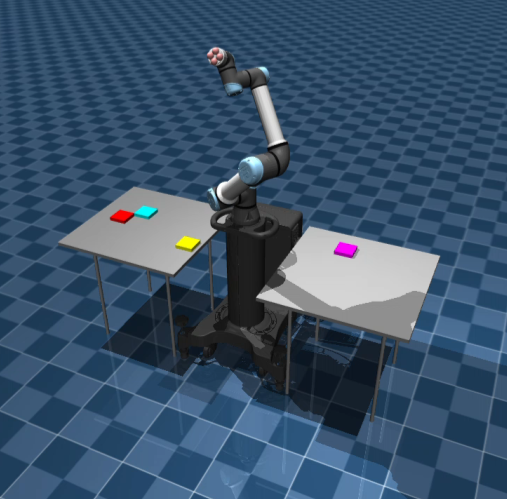

In the next tutorials, we will:

* meet the robot arm and its **kinematics**: how joint positions determine where the gripper is (forward kinematics), and how to find joint positions that bring the gripper to a desired place (inverse kinematics),
* see how to move between configurations without hitting anything with **motion planning**,
* make the robot actually follow those motions with **control**,
* estimate where things are from noisy observations with **state estimation**,
* and finally, put it all together with **task and motion planning**, first with the task planner and the motion planner working in turns, and then integrated.